In [1]:

import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Just testing on how equations represent graphs 
1. z = wx + b
2. tanh function activation function (this is specific to nn(neural networks) before training not relate to testing on how tanh looks because we knew it how it looks)

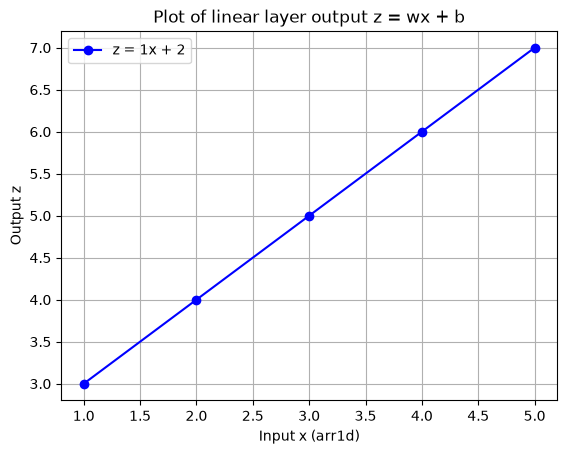

In [ ]:


arr1d = np.array([1, 2, 3, 4, 5])

# 2. Model Parameters
b = 2  # Bias
w = 1  # Weight (Slope)

# 3. Linear combination (z = wx + b)
z = w * arr1d + b  # Evaluates to array([3, 4, 5, 6, 7])

# 4. Plotting
plt.plot(arr1d, z, marker="o", color="b", label=f"z = {w}x + {b}")
plt.xlabel("Input x (arr1d)")
plt.ylabel("Output z")
plt.title("Plot of linear layer output z = wx + b")
plt.grid(True)
plt.legend()
plt.show()

explain where do we get the z value :
1. assumption is that we get the w value from the activation function slop 
2. and x is the encoding schema number 


Truth: 
1. z is the w or the weight of the neuron. (it is set to be random initially and this is the number which is updated during backpropagation )
2. x is the encoded schema number 

Layers:
1. z = wx + b 
2. z = wa + b

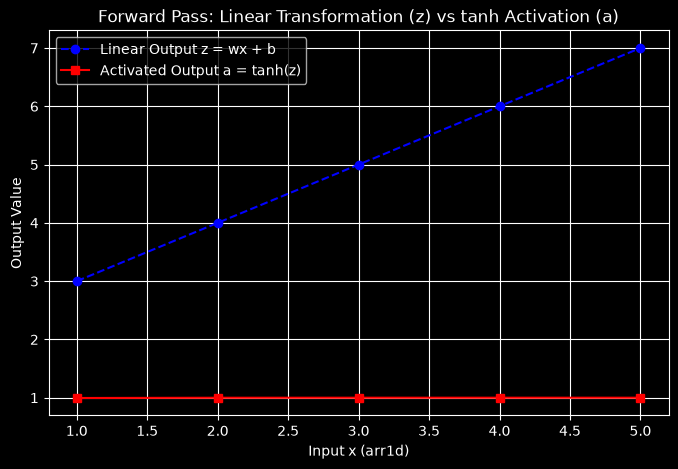

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Inputs (x values)
arr1d = np.array([1, 2, 3, 4, 5])

plt.style.use("dark_background")

# 2. Model Parameters
b = 2  # Bias
w = 1  # Weight (Slope)

# 3. Linear combination: z = wx + b
z = w * arr1d + b  # array([3, 4, 5, 6, 7])

# 4. Activation Function: a = tanh(z)
a = np.tanh(z)     # Squashes outputs into range (-1, 1)

# --- Plotting ---
plt.figure(figsize=(8, 5))

# Plot linear output (z)
plt.plot(arr1d, z, marker="o", linestyle="--", color="b", label="Linear Output z = wx + b")

# Plot activation output (a = tanh(z))
plt.plot(arr1d, a, marker="s", linestyle="-", color="r", label="Activated Output a = tanh(z)")

plt.xlabel("Input x (arr1d)")
plt.ylabel("Output Value")
plt.title("Forward Pass: Linear Transformation (z) vs tanh Activation (a)")
plt.grid(True)
plt.legend()
plt.show()

# Manual backprop

In [ ]:
class Value:

    def __init__(self, data, _children=(), _op ='', label='' ): # _op is operation  and by default it is a leaf 
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        
        

    def __repr__(self):
        return f"value(data = {self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+' )
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out 

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L
    

value(data = -8.0)

In [3]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad= %.4f  }" % (n.label, n.data, n.grad), shape='record')
    
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

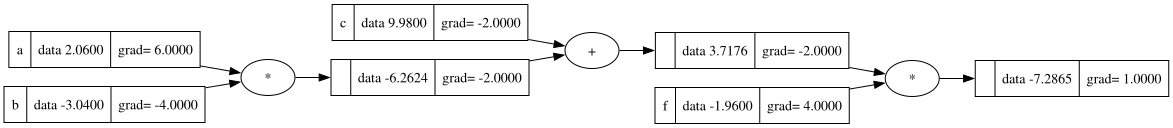

In [ ]:
draw_dot(L)

In [59]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f

print(L.data)

-7.286496


In [61]:
L.grad = 1.00
d.grad = -2
f.grad = 4
c.grad = -2
e.grad = -2
a.grad = 6
b.grad = -4




def lol():
  
  h = 0.001
  
  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f; L.label = 'L'
  L1 = L.data

  
  a = Value(2.0, label='a')

  b = Value(-3.0, label='b')
  b.data += h
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')

  L = d * f; L.label = 'L'
  L2 = L.data 
  
  print((L2 - L1)/h)
  
lol()

-3.9999999999995595


# semicolon seperate lines 

In python we can use semicolon 

In [42]:
print("hello") ; print("hi")
b= "hey! " ; c= "hello" ; print(b + c)

hello
hi
hey! hello


403.4287934927351

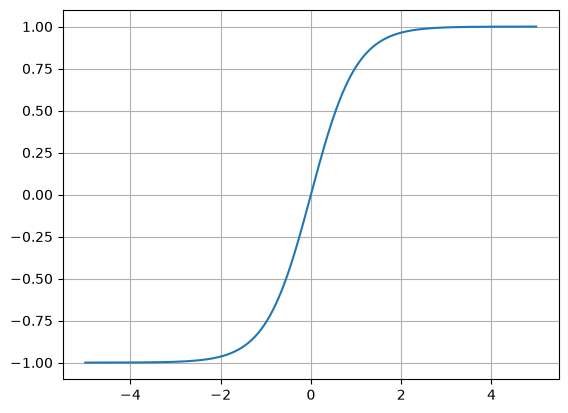

In [79]:
plt.plot(np.arange(-5,5,0.01), np.tanh(np.arange(-5,5,0.01))); plt.grid()
math.exp(2*3)

In [80]:
math.exp(2*3)

403.4287934927351

# Automated backprop from Andrij 

In [1]:
class Value:
    def __init__(self, data, _children=(), _op='', label=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda : None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) -1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L
         

Value(data=-8.0)

 what is reversed() in python => 


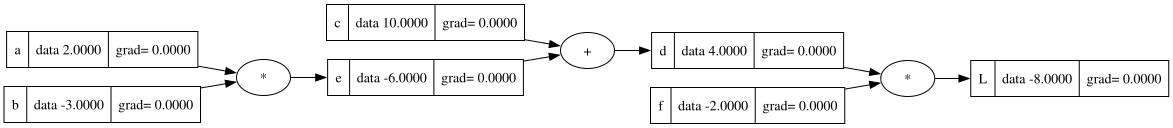

In [4]:
draw_dot(L)